# M06-6 (Optional) | weight_norm in QAT: Keep g, v During Training and Strip It From the Graph Only Before convert

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m06_qat_pipeline/06_weight_norm_qat.ipynb)

What `weight_norm` is, what it looks like after export, and how PTQ handles it: see M05-5.
PTQ does not train, so removing weight_norm costs nothing; QAT does train, and `remove_parametrizations` before export amounts to giving up training $g$ and $v$.
This notebook looks at how to "keep it until training ends":

- **A.** No BN: $g$ and $v$ both get gradients and both get updated; convert folds `_weight_norm` into a constant, and no extra handling is needed.
- **B.** With BN: `prepare_qat_pt2e` succeeds, and `convert_pt2e` raises `ValueError` when folding BN.
- **C.** Fix: after training and before convert, use `strip_weight_norm` to turn the weight back into a `get_attr`.

For the basic graph-editing moves see M00-4; for the QAT conv + BN subgraph see M04-2.

In [1]:
#| include: false
# When running on Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m06_qat_pipeline")

In [2]:
import copy

import torch

from common.models import ConvBnReLU, ConvReLU, example_inputs
from common.pt2e import convert_pt2e, export_module, prepare_qat_pt2e, quiet
from common.qat import freeze_for_eval, qat_quantizer
from common.viz import draw, draw_stages, table
from common.weight_norm import add_weight_norm, strip_weight_norm

quiet()
_ = torch.manual_seed(0)


def make(cls):
    """Small model: warm BN up with a few batches, then apply weight_norm to conv.weight."""
    torch.manual_seed(0)
    m = cls(3, 8).train()
    with torch.no_grad():
        for _ in range(3):
            m(torch.randn(16, 3, 16, 16))
    add_weight_norm(m.eval())
    return m


def prepare(model):
    return prepare_qat_pt2e(export_module(model, example_inputs(), train=True), qat_quantizer(bits=8))


def short_train(prepared, steps=5):
    """A few SGD steps, only to confirm that g and v get updated; the loss is arbitrary."""
    opt = torch.optim.SGD(prepared.parameters(), lr=1e-2)
    for _ in range(steps):
        opt.zero_grad()
        prepared(torch.randn(16, 3, 16, 16)).pow(2).mean().backward()
        opt.step()

`add_weight_norm` and `strip_weight_norm` are this project's tools (`common/weight_norm.py`), introduced in M05-5; for `qat_quantizer` and `freeze_for_eval` see M06-1 and M06-2.

## A. No BN: Both g and v Are Trained

Apply weight_norm to conv + relu, then run `prepare_qat_pt2e`:

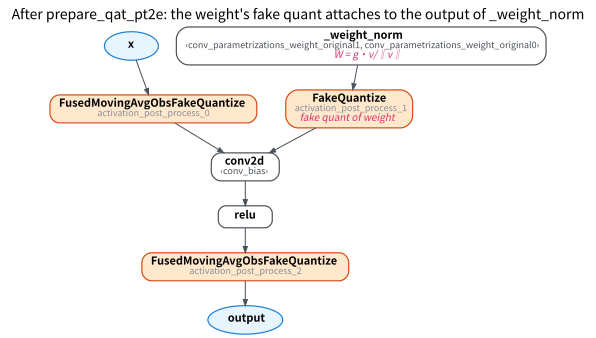

In [3]:
p = prepare(make(ConvReLU))
NOTES = {"_weight_norm": "W = g·v/‖v‖", "activation_post_process_1": "fake quant of weight"}
draw(p, title="After prepare_qat_pt2e: the weight's fake quant attaches to the output of _weight_norm", notes=NOTES)

The weight's fake quant attaches to the output of `_weight_norm`, so it quantizes the computed $W$, at the same position as the observer in PTQ (M05-5).
Train a few steps and see which parameters get gradients and updates:

In [4]:
params = dict(p.named_parameters())
before = {k: v.detach().clone() for k, v in params.items()}
short_train(p)
updated = {k: (v.grad is not None and bool(v.grad.abs().sum() > 0), not torch.equal(v, before[k])) for k, v in params.items()}
table([[k, g, u] for k, (g, u) in updated.items()], ["Parameter", "Has gradient", "Updated"])

Parameter,Has gradient,Updated
conv.bias,True,True
conv.parametrizations.weight.original0,True,True
conv.parametrizations.weight.original1,True,True


In [5]:
assert all(g and u for g, u in updated.values())
assert any("original0" in k for k in updated) and any("original1" in k for k in updated)

`original0` is $g$ and `original1` is $v$. The STE gradient passes through the fake quant and then flows back to $g$ and $v$ through `_weight_norm`, so what QAT trains is $g$ and $v$, and the re-parametrization stays in effect. How the gradients of $g$ and $v$ are derived, and what this split buys for optimization, is in the blog post "[Notes on Weight Normalization](https://bobondemon.github.io/2022/09/26/Weight-Normalization-%E7%9A%84%E7%AD%86%E8%A8%98/#%E5%B0%8D%E5%A4%A7%E5%B0%8F-g-%E7%9A%84%E5%BE%AE%E5%88%86)" (in Chinese).

Without BN, convert needs no extra handling:

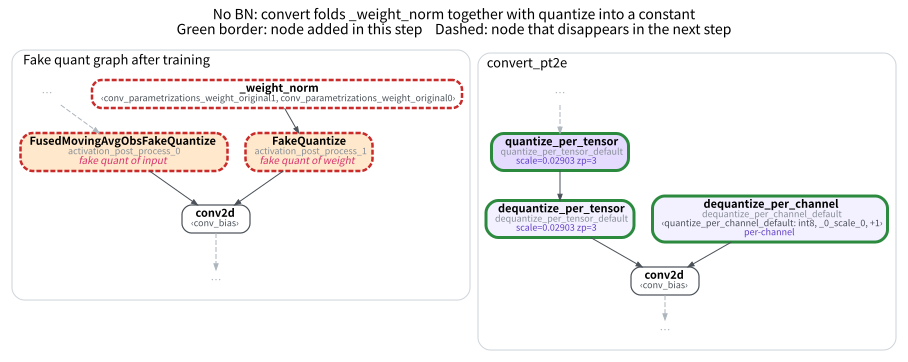

In [6]:
freeze_for_eval(p)
c = convert_pt2e(copy.deepcopy(p))
draw_stages([(p, "Fake quant graph after training"), (c, "convert_pt2e")],
            focus=["_weight_norm", "activation_post_process_0", "activation_post_process_1", "conv2d"], hops=0,
            notes=[{"activation_post_process_0": "fake quant of input", "activation_post_process_1": "fake quant of weight"}, {}],
            title="No BN: convert folds _weight_norm together with quantize into a constant")

In [7]:
assert "_weight_norm" not in {n.name for n in c.graph.nodes}

The two fake quants in the left graph are replaced by different things after convert:

- **The input's fake quant** → `quantize_per_tensor` + `dequantize_per_tensor`: the input values are only known at run time, so the q/dq stays in the graph (the two green boxes at the top of the right graph).
- **The weight's fake quant together with `_weight_norm`** → an int8 constant + `dequantize_per_channel`: all inputs of `_weight_norm` are constants, and convert defaults to `fold_quantize=True`, so it precomputes this together with the weight's quantize into an int8 constant (the same as M05-5 B), leaving only the dequantize in the right graph.

## B. With BN: prepare Succeeds, convert Fails

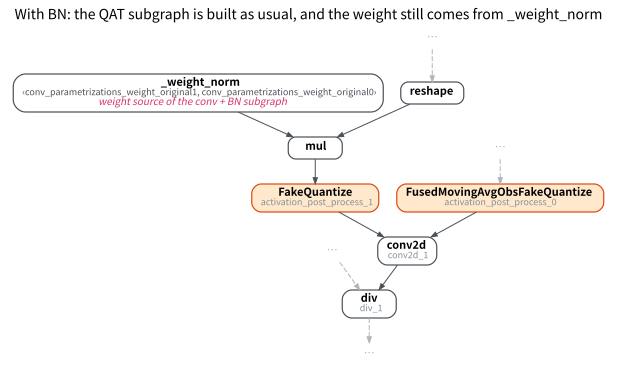

In [8]:
p_bn = prepare(make(ConvBnReLU))
FOCUS = ["_weight_norm", "mul", "activation_post_process_1", "conv2d_1"]
draw(p_bn, focus=FOCUS, hops=1, notes={"_weight_norm": "weight source of the conv + BN subgraph"},
     title="With BN: the QAT subgraph is built as usual, and the weight still comes from _weight_norm")

`prepare_qat_pt2e` does not fold BN; it replaces conv + BN with the QAT subgraph (M04-2): the weight is first multiplied by BN's coefficient (`mul`) and then goes into the fake quant.
The pattern match that builds the subgraph does not care where the weight comes from, so it can be built with `_weight_norm` attached and training runs as usual. The problem is at the last step:

In [9]:
short_train(p_bn)
freeze_for_eval(p_bn)
try:
    convert_pt2e(copy.deepcopy(p_bn))
    error = None
except ValueError as e:
    error = e
print("convert_pt2e →", f"{type(error).__name__}: {error}")
assert error is not None

convert_pt2e → ValueError: Expected get_attr node, got call_function


`convert_pt2e` has to actually fold BN into conv (`_fold_conv_bn_qat`, one of the five steps in M02-3), which requires reading the weight out as a constant and rewriting it.
The torchao internal function that reads constants accepts only `get_attr` (from reading the torchao 0.18 source), so it fails when the weight is the `call_function` `_weight_norm`.
The difference from PTQ is when it fails: PTQ fails right at the start of `prepare_pt2e` (M05-5), while QAT fails only at convert, after all the training is done.

## C. Fix: After Training and Before convert, Turn the Weight Back Into get_attr

`strip_weight_norm(gm)` computes the weight with the same `_weight_norm` and the same $g$, $v$ in the graph, stores it as a parameter, inserts a `get_attr` node, uses `replace_all_uses_with` to rewire downstream consumers to it, and then deletes `_weight_norm` (the graph-editing moves of M00-4):

Weight stripped: ['conv.weight']
Parameters after strip: ['conv.weight', 'bn.weight', 'bn.bias']


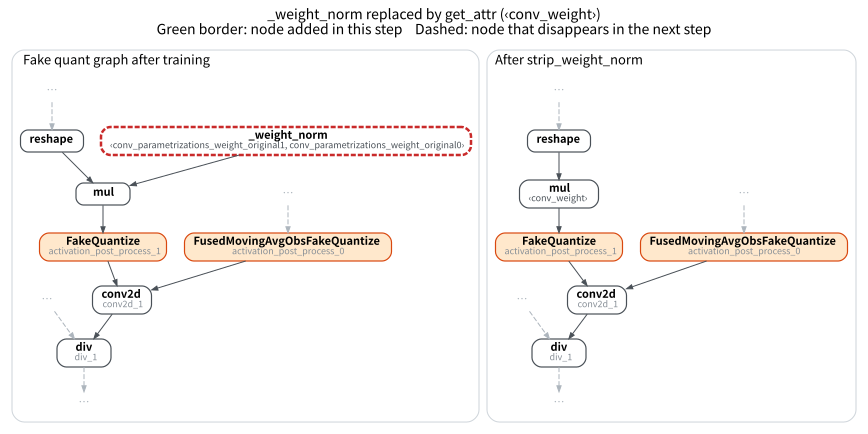

In [10]:
fixed = copy.deepcopy(p_bn)
x = torch.randn(32, 3, 16, 16)
with torch.no_grad():
    y_before = fixed(x)
print("Weight stripped:", strip_weight_norm(fixed))
print("Parameters after strip:", [n for n, _ in fixed.named_parameters()])
draw_stages([(p_bn, "Fake quant graph after training"), (fixed, "After strip_weight_norm")], focus=FOCUS, hops=1,
            title="_weight_norm replaced by get_attr (‹conv_weight›)")

The weight input of `mul` in the graph is now `‹conv_weight›`. Now convert works, and BN is folded into conv too:

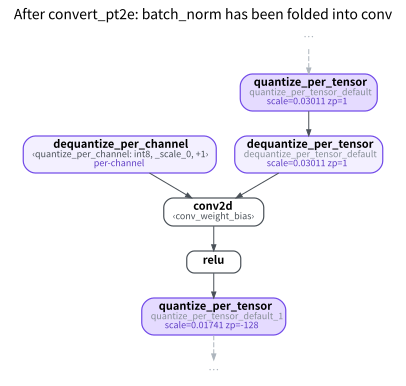

In [11]:
converted = convert_pt2e(copy.deepcopy(fixed))
draw(converted, focus=lambda n: n.name.startswith("conv2d"), hops=2, title="After convert_pt2e: batch_norm has been folded into conv")

In [12]:
with torch.no_grad():
    y_after, y_conv = fixed(x), converted(x)
checks = {"Fake quant graph before vs after strip (torch.equal)": torch.equal(y_before, y_after),
          "Fake quant graph after strip vs convert graph (torch.allclose)": torch.allclose(y_after, y_conv)}
table([[k, v] for k, v in checks.items()], ["Output on the same 32 inputs", "Result"])

Output on the same 32 inputs,Result
Fake quant graph before vs after strip (torch.equal),True
Fake quant graph after strip vs convert graph (torch.allclose),True


In [13]:
assert all(checks.values())
assert not any("batch_norm" in str(n.target) for n in converted.graph.nodes)

The two checks each test one thing:

- **Bitwise identical before and after strip**: checks that the graph edit was wired correctly. The weight is computed by the same op with the same $g$, $v$, so the values are necessarily identical; what can go wrong is which parameter the new `get_attr` points to, and whether all downstream consumers were rewired.
- **The convert graph matches the fake quant graph**: section B failed at this step; here it runs through, and the outputs agree, which shows that folding BN read the correct weight.

Why strip only **after** training: once it is stripped, the graph holds only the constant $W$, so calling it before training is equivalent to `remove_parametrizations`, giving up training $g$ and $v$.

## Summary

- In QAT the fake quant attaches to the output of `_weight_norm`, and gradients flow back through it to $g$ and $v$.
- Without BN there is nothing to handle; with BN, `prepare_qat_pt2e` passes and only `convert_pt2e` fails when folding BN.
- Flow: `export(train=True)` → `prepare_qat_pt2e` → training → `freeze_for_eval` → `strip_weight_norm` → `convert_pt2e`.
- This notebook does not compare the effect of weight_norm on QAT accuracy.